# Oulu airport temperature forecasting with TimesFM 3.0

Zero-shot forecasting of hourly air temperature at Oulu airport, Finland, with Google's [TimesFM 3.0](https://github.com/google-research/timesfm) foundation model and open data from the Finnish Meteorological Institute (FMI).

Prediction task: given the hourly temperature history up to now, predict the next 72 hours, with a 10-90% uncertainty band.

TimesFM is pretrained and used as is with no fine-tuning. The history from 2010 to 2025 is used as model context and to build a climatology baseline. 2026 is used for testing.

## Setup

In [16]:
import time
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from timesfm3 import ModelConfig, TimesFM3Evaluator

TZ = "Europe/Helsinki"
HISTORY_CSV = "data/oulu_airport_2010_2025.csv"
TEST_CSV = "data/oulu_airport_2026.csv"
TEST_START = pd.Timestamp("2026-01-01", tz=TZ)

CONTEXT = 2048   # hours of history given to the model (about 3 months)
HORIZON = 72     # hours to predict

plt.rcParams["figure.figsize"] = (14, 4)

In [17]:
model = TimesFM3Evaluator(ModelConfig(
    checkpoint_path="google/timesfm-3.0-pytorch",
    per_core_batch_size=32,
    device="cuda",
))

def forecast(contexts, horizon):
    """Forecast a batch of 1D series. Returns median (n, h) and deciles (n, h, 9)."""
    outs = list(model.predict_batch(
        contexts=[np.asarray(c, dtype=np.float32) for c in contexts],
        horizon=horizon,
        return_quantiles=True,
        use_symmetric_averaging=False,
    ))
    point = np.stack([np.asarray(o.forecast).reshape(horizon) for o in outs])
    quant = np.stack([np.asarray(o.quantiles).reshape(horizon, 9) for o in outs])
    return point, quant

## Data

Hourly mean temperature from FMI's Download observations service, station Oulu airport. The FMI record available for this station starts in June 2019. Times are local. Every October one hour appears twice when the clocks go back, so the first copy is treated as summer time and the second as winter time.

In [18]:
def load_fmi_csv(path):
    df = pd.read_csv(path, low_memory=False)
    time_col = next(c for c in df.columns if c.startswith("Time"))
    temp_col = next(c for c in df.columns if "temperature" in c.lower())
    naive = pd.to_datetime(dict(year=df["Year"], month=df["Month"], day=df["Day"]))
    naive = naive + pd.to_timedelta(df[time_col].astype(str) + ":00")
    first_copy = ~naive.duplicated(keep="first").values
    stamps = naive.dt.tz_localize(TZ, ambiguous=first_copy, nonexistent="NaT")
    s = pd.Series(pd.to_numeric(df[temp_col], errors="coerce").values,
                  index=pd.DatetimeIndex(stamps), name="temp")
    s = s[s.index.notna()]
    return s[~s.index.duplicated()].sort_index()

raw = pd.concat([load_fmi_csv(HISTORY_CSV), load_fmi_csv(TEST_CSV)]).sort_index()
raw = raw[~raw.index.duplicated()].asfreq("h")

isna = raw.isna()
run_id = isna.ne(isna.shift()).cumsum()
run_len = isna.groupby(run_id).transform("sum")
print(f"{raw.index.min():%Y-%m-%d} to {raw.index.max():%Y-%m-%d %H:%M}, {len(raw):,} hours")
print(f"Missing hours: {isna.sum()}, longest gap: {run_len[isna].max() if isna.any() else 0} hours")

2019-06-10 to 2026-10-17 03:00, 64,454 hours
Missing hours: 54, longest gap: 27 hours


Climatology is the normal temperature for a given day of year and hour. It is built from data before 2026 only, so the test year never leaks in. It is used as a baseline and to fill long gaps.

Gaps up to 6 hours are interpolated. Longer gaps are filled with climatology instead of a long straight line, so the model is not fed fake data.

In [19]:
def climatology(s, smooth_days=15):
    s = s.dropna()
    table = s.groupby([s.index.dayofyear, s.index.hour]).mean().unstack()
    table = table.reindex(index=range(1, 367), columns=range(24)).interpolate(limit_direction="both")
    pad = smooth_days // 2
    wrapped = pd.concat([table.iloc[-pad:], table, table.iloc[:pad]])  # 31 Dec next to 1 Jan
    out = wrapped.rolling(smooth_days, center=True).mean().iloc[pad:-pad]
    out.index = table.index
    return out

def clim_values(table, index):
    index = pd.DatetimeIndex(index)
    return table.values[index.dayofyear - 1, index.hour].astype(np.float32)

clim = climatology(raw[raw.index < TEST_START])

short = isna & (run_len <= 6)
long_ = isna & ~short
temp = raw.where(~short, raw.interpolate(limit_area="inside"))
temp[long_] = clim_values(clim, temp.index[long_])
temp = temp.interpolate(limit_direction="both")
print(f"Interpolated {short.sum()} hours, filled {long_.sum()} hours from climatology")

y = temp.values.astype(np.float32)

Interpolated 27 hours, filled 27 hours from climatology


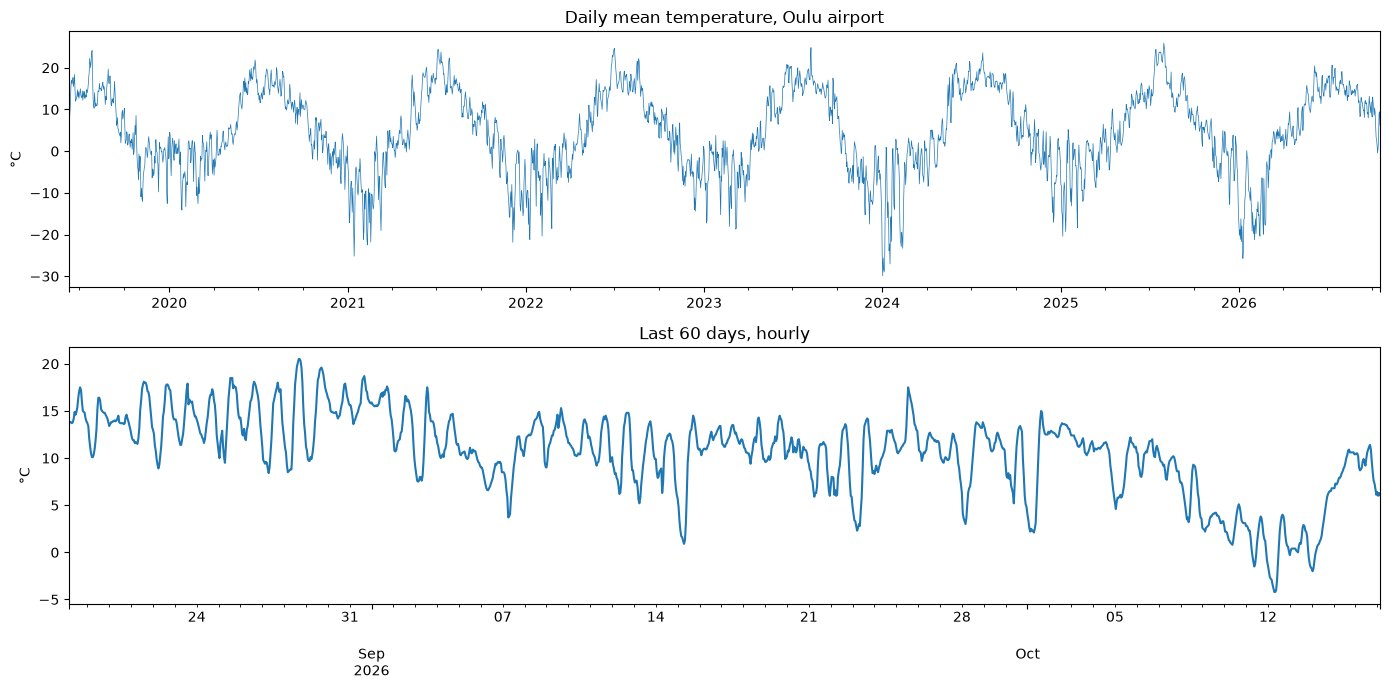

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
temp.resample("D").mean().plot(ax=axes[0], linewidth=0.5)
axes[0].set_title("Daily mean temperature, Oulu airport")
temp.iloc[-24 * 60:].plot(ax=axes[1])
axes[1].set_title("Last 60 days, hourly")
for ax in axes:
    ax.set_ylabel("°C")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

## Prediction: the next 72 hours

The model gets the last 2048 hours (about 3 months) and predicts the next 72. The shaded
area is the 10-90% band: the model expects the real temperature to fall inside it 80% of
the time.

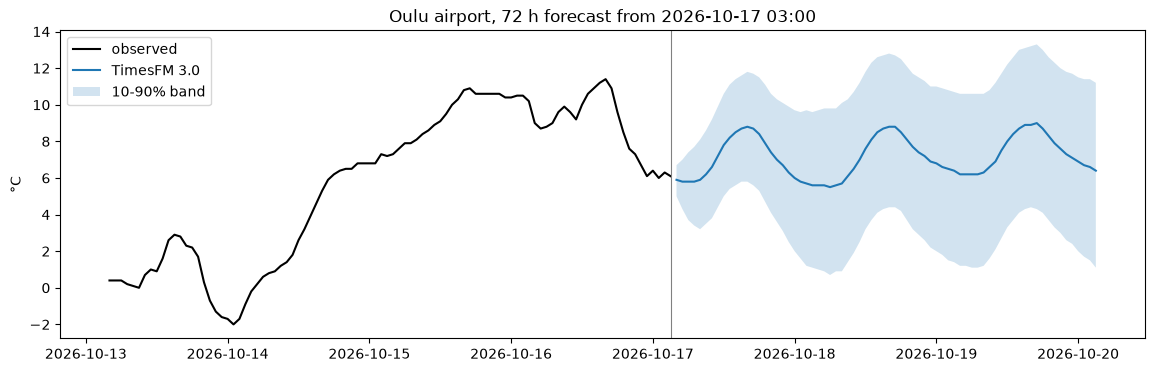

,forecast,low_10,high_90
time,,,
2026-10-17 04:00:00+03:00,5.9,5.0,6.7
2026-10-17 09:00:00+03:00,6.2,3.5,8.6
2026-10-17 15:00:00+03:00,8.7,5.8,11.6
2026-10-18 03:00:00+03:00,5.6,1.1,9.6
2026-10-18 15:00:00+03:00,8.7,4.3,12.7
2026-10-19 03:00:00+03:00,6.4,1.4,10.7
2026-10-20 03:00:00+03:00,6.4,1.1,11.2


In [21]:
issued = temp.index[-1]
point, quant = forecast([y[-CONTEXT:]], HORIZON)
future = pd.date_range(issued + pd.Timedelta(hours=1), periods=HORIZON, freq="h")

prediction = pd.DataFrame({
    "forecast": point[0].round(1),
    "low_10": quant[0, :, 0].round(1),
    "high_90": quant[0, :, 8].round(1),
}, index=pd.Index(future, name="time"))
prediction.to_csv("oulu_prediction_next_72h.csv")

plt.plot(temp.index[-96:], y[-96:], color="black", label="observed")
plt.plot(future, prediction["forecast"], label="TimesFM 3.0")
plt.fill_between(future, prediction["low_10"], prediction["high_90"], alpha=0.2, label="10-90% band")
plt.axvline(issued, color="grey", linewidth=0.8)
plt.ylabel("°C")
plt.title(f"Oulu airport, 72 h forecast from {issued:%Y-%m-%d %H:%M}")
plt.legend()
plt.show()

prediction.iloc[[0, 5, 11, 23, 35, 47, 71]]

In [22]:
# Daily summary of the prediction
daily = prediction.groupby(prediction.index.date).agg(
    min=("forecast", "min"), max=("forecast", "max"), mean=("forecast", "mean")).round(1)
daily

,min,max,mean
2026-10-17,5.8,8.8,7.2
2026-10-18,5.5,8.8,7.0
2026-10-19,6.2,9.0,7.4
2026-10-20,6.4,6.9,6.6


## Live prediction from the FMI API

The same prediction but with the newest observations pulled directly from FMI open data, next to FMI's own forecast (HARMONIE weather model). The place name Oulunsalo resolves to the Oulu airport station. FMI rejects long time ranges, so data is fetched in 14 day chunks.

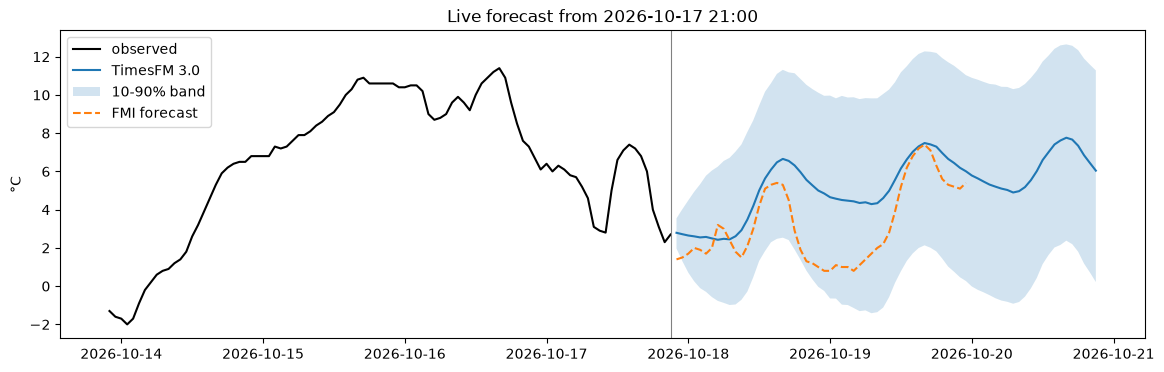

,TimesFM,FMI
2026-10-17 22:00:00+03:00,2.8,1.4
2026-10-18 03:00:00+03:00,2.6,1.7
2026-10-18 09:00:00+03:00,2.9,1.5
2026-10-18 21:00:00+03:00,5.3,1.2
2026-10-19 21:00:00+03:00,6.4,5.2


In [23]:
FMI_WFS = "https://opendata.fmi.fi/wfs"
BS = "{http://xml.fmi.fi/schema/wfs/2.0}"

def fmi_query(**params):
    base = {"service": "WFS", "version": "2.0.0", "request": "getFeature", "place": "Oulunsalo"}
    r = requests.get(FMI_WFS, params={**base, **params}, timeout=60)
    r.raise_for_status()
    rows = [(el.find(f"{BS}Time").text, float(el.find(f"{BS}ParameterValue").text))
            for el in ET.fromstring(r.content).iter(f"{BS}BsWfsElement")]
    t, v = zip(*rows)
    s = pd.Series(v, index=pd.to_datetime(list(t), utc=True).tz_convert(TZ))
    return s[~s.index.duplicated()].sort_index()

def fetch_observations(days):
    end = pd.Timestamp.now(tz="UTC").floor("h")
    t, parts = end - pd.Timedelta(days=days), []
    while t < end:
        t2 = min(t + pd.Timedelta(days=14), end)
        parts.append(fmi_query(
            storedquery_id="fmi::observations::weather::hourly::simple",
            parameters="TA_PT1H_AVG",
            starttime=f"{t:%Y-%m-%dT%H:%M:%SZ}", endtime=f"{t2:%Y-%m-%dT%H:%M:%SZ}"))
        t = t2
        time.sleep(0.5)
    s = pd.concat(parts)
    s = s[~s.index.duplicated()]
    return s.loc[:s.last_valid_index()].asfreq("h").interpolate(limit_direction="both")

live = fetch_observations(days=CONTEXT // 24 + 3)
fmi_fc = fmi_query(storedquery_id="fmi::forecast::harmonie::surface::point::simple",
                   parameters="Temperature", timestep=60)

live_issued = live.index[-1]
lp, lq = forecast([live.values[-CONTEXT:]], HORIZON)
live_future = pd.date_range(live_issued + pd.Timedelta(hours=1), periods=HORIZON, freq="h")
fmi_fc = fmi_fc.reindex(live_future)

plt.plot(live.index[-96:], live.values[-96:], color="black", label="observed")
plt.plot(live_future, lp[0], label="TimesFM 3.0")
plt.fill_between(live_future, lq[0, :, 0], lq[0, :, 8], alpha=0.2, label="10-90% band")
plt.plot(live_future, fmi_fc.values, "--", label="FMI forecast")
plt.axvline(live_issued, color="grey", linewidth=0.8)
plt.ylabel("°C")
plt.title(f"Live forecast from {live_issued:%Y-%m-%d %H:%M}")
plt.legend()
plt.show()

pd.DataFrame({"TimesFM": lp[0].round(1), "FMI": fmi_fc.values}, index=live_future).iloc[[0, 5, 11, 23, 47]]

Every live run is appended to live_forecasts.csv, so TimesFM and FMI can be scored against what really happened once the target hours have passed.

In [29]:
LIVE_LOG = "live_forecasts.csv"

log_rows = pd.DataFrame({
    "issued_at": live_issued,
    "lead_hours": np.arange(1, HORIZON + 1),
    "timesfm": lp[0].round(2),
    "q10": lq[0, :, 0].round(2),
    "q90": lq[0, :, 8].round(2),
    "fmi": fmi_fc.values,
}, index=pd.Index(live_future, name="target_time"))

import os
log_rows.to_csv(LIVE_LOG, mode="a", header=not os.path.exists(LIVE_LOG))
print(f"Logged forecast issued {live_issued:%Y-%m-%d %H:%M}")

Logged forecast issued 2026-10-17 21:00


Scoring the live forecasts. Run the live cell a few times over several days, then run this cell. It compares TimesFM and FMI only on hours where both made a forecast.

In [30]:
log = pd.read_csv(LIVE_LOG).drop_duplicates(["issued_at", "lead_hours"], keep="last")
log["target_time"] = pd.to_datetime(log["target_time"], utc=True).dt.tz_convert(TZ)
log = log[log["target_time"] <= live.index[-1]]
log["actual"] = log["target_time"].map(live)
scored = log.dropna(subset=["actual", "fmi"])

if scored.empty:
    print("Nothing to score yet. Come back after some forecast hours have passed.")
else:
    scored = scored.assign(TimesFM=(scored["timesfm"] - scored["actual"]).abs(),
                           FMI=(scored["fmi"] - scored["actual"]).abs())
    by_lead = scored.groupby((scored["lead_hours"] - 1) // 6 * 6 + 6)[["TimesFM", "FMI"]].mean()
    by_lead.index.name = "hours ahead (up to)"
    inside = ((scored["actual"] >= scored["q10"]) & (scored["actual"] <= scored["q90"])).mean()
    print(f"{scored['issued_at'].nunique()} forecasts, {len(scored)} scored hours, "
          f"TimesFM band coverage {inside:.0%}")
    display(by_lead.round(2))

Nothing to score yet. Come back after some forecast hours have passed.


## Evaluation: backtest over all of 2026

How much should we trust that prediction? A 72 hour forecast is issued at every midnight in 2026 using only data before that midnight and compared with what happened.

Baselines
- Persistence: the temperature stays the same as the last observation
- Yesterday: repeat the last 24 hours
- Climatology: the normal temperature for that day and hour (2010 to 2025)

TimesFM is run with four context lengths to see if a longer memory helps.

In [24]:
last_day = (temp.index.max() - pd.Timedelta(hours=HORIZON - 1)).normalize()
days = pd.date_range(TEST_START, last_day, freq="D")
starts = np.array([temp.index.get_loc(d) for d in days])
actual = np.stack([y[s:s + HORIZON] for s in starts])
print(f"{len(days)} forecasts from {days[0]:%d %b} to {days[-1]:%d %b %Y}")

preds = {
    "persistence": np.stack([np.repeat(y[s - 1], HORIZON) for s in starts]),
    "yesterday": np.stack([np.tile(y[s - 24:s], HORIZON // 24) for s in starts]),
    "climatology": np.stack([clim_values(clim, temp.index[s:s + HORIZON]) for s in starts]),
}
bands = {}
for c in [512, 2048, 8760, 15360]:   # 3 weeks, 3 months, 1 year, 1.75 years
    f, q = forecast([y[s - c:s] for s in starts], HORIZON)
    preds[f"TimesFM ctx {c}"] = f
    bands[f"TimesFM ctx {c}"] = ((actual >= q[:, :, 0]) & (actual <= q[:, :, 8])).mean()
    print(f"context {c} done")

287 forecasts from 01 Jan to 14 Oct 2026
context 512 done
context 2048 done
context 8760 done
context 15360 done


In [25]:
mae_lead = pd.DataFrame({k: np.abs(v - actual).mean(axis=0) for k, v in preds.items()},
                        index=pd.Index(range(1, HORIZON + 1), name="hours ahead"))

summary = mae_lead.loc[[1, 6, 24, 48, 72]].T.round(2)
summary.columns = [f"{h}h" for h in summary.columns]
summary["mean"] = mae_lead.mean().round(2)
summary["10-90% band"] = pd.Series(bands).map("{:.0%}".format)
summary.to_csv("oulu_2026_backtest_summary.csv")
summary.fillna("")

,1h,6h,24h,48h,72h,mean,10-90% band
persistence,0.65,2.29,2.66,3.37,3.61,3.33,
yesterday,2.72,3.11,2.66,3.37,3.61,3.22,
climatology,3.85,3.88,3.87,3.85,3.82,3.94,
TimesFM ctx 512,0.37,1.42,2.51,3.10,3.39,2.77,81%
TimesFM ctx 2048,0.37,1.40,2.61,3.27,3.51,2.84,81%
TimesFM ctx 8760,0.37,1.39,2.54,3.16,3.37,2.72,81%
TimesFM ctx 15360,0.37,1.38,2.53,3.19,3.40,2.74,82%


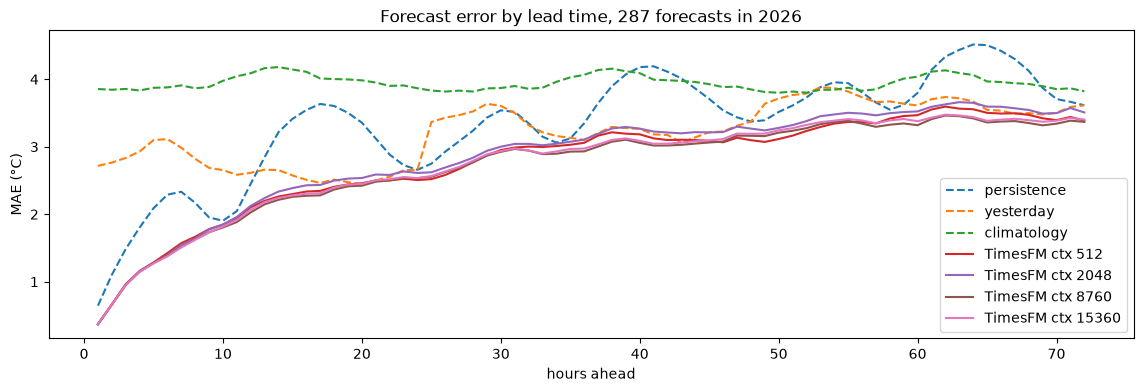

In [26]:
for k in mae_lead:
    plt.plot(mae_lead.index, mae_lead[k], "-" if k.startswith("TimesFM") else "--", label=k)
plt.xlabel("hours ahead")
plt.ylabel("MAE (°C)")
plt.title(f"Forecast error by lead time, {len(days)} forecasts in 2026")
plt.legend()
plt.show()

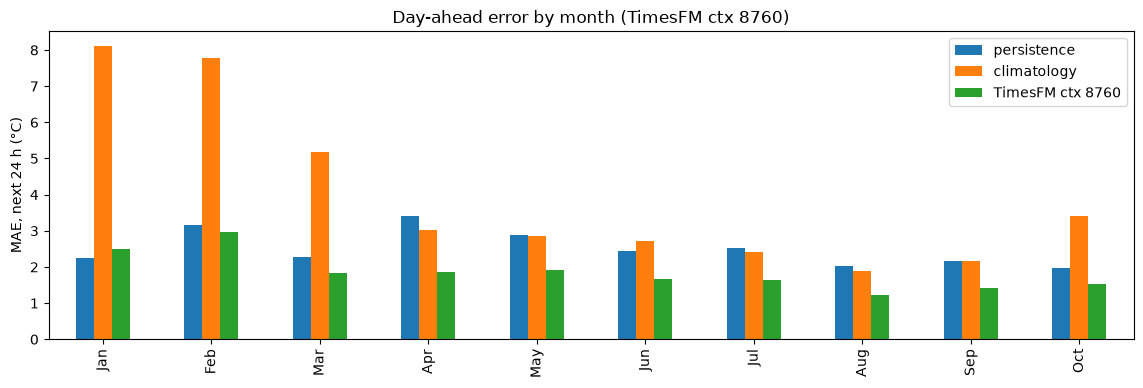

In [27]:
# Day-ahead error by month: where does the model struggle?
best = mae_lead.filter(like="TimesFM").mean().idxmin()
monthly = pd.DataFrame({k: np.abs(preds[k][:, :24] - actual[:, :24]).mean(axis=1)
                        for k in ["persistence", "climatology", best]}, index=days)
monthly = monthly.groupby(days.month).mean()
monthly.index = [pd.Timestamp(2026, m, 1).strftime("%b") for m in monthly.index]
monthly.plot(kind="bar")
plt.ylabel("MAE, next 24 h (°C)")
plt.title(f"Day-ahead error by month ({best})")
plt.show()

### Is the difference real?

287 forecasts is a decent sample but weather comes in spells of several days, so neighbouring days are not independent. This compares two methods on the same days and uses a block bootstrap (7 day blocks) for a 95% confidence interval of the MAE gain. If the interval does not include 0, the gain is unlikely to be luck.

In [31]:
rng = np.random.default_rng(0)

def block_bootstrap_means(d, block=7, n=5000):
    n_blocks = int(np.ceil(len(d) / block))
    starts = rng.integers(0, len(d) - block + 1, size=(n, n_blocks))
    idx = (starts[..., None] + np.arange(block)).reshape(n, -1)[:, :len(d)]
    return d[idx].mean(axis=1)

def compare(a, b, leads=(1, 6, 12, 24, 48, 72)):
    """Positive gain means `a` has lower error than `b`."""
    rows = {}
    for h in list(leads) + ["all"]:
        sl = slice(None) if h == "all" else slice(h - 1, h)
        ea = np.abs(preds[a][:, sl] - actual[:, sl]).mean(axis=1)
        eb = np.abs(preds[b][:, sl] - actual[:, sl]).mean(axis=1)
        d = eb - ea
        boot = block_bootstrap_means(d)
        rows["mean 1-72h" if h == "all" else f"{h}h"] = {
            "MAE gain (°C)": d.mean(),
            "95% CI low": np.percentile(boot, 2.5),
            "95% CI high": np.percentile(boot, 97.5),
            "days a is better": f"{(ea < eb).mean():.0%}",
        }
    out = pd.DataFrame(rows).T
    return out.astype({c: float for c in out.columns[:3]}).round(2)

print(f"a = {best}, b = persistence")
display(compare(best, "persistence"))
print(f"a = {best}, b = yesterday")
display(compare(best, "yesterday"))
print("a = TimesFM ctx 8760 (1 year), b = TimesFM ctx 2048 (3 months)")
display(compare("TimesFM ctx 8760", "TimesFM ctx 2048"))

a = TimesFM ctx 8760, b = persistence


,MAE gain (°C),95% CI low,95% CI high,days a is better
1h,0.28,0.21,0.36,75%
6h,0.90,0.68,1.19,71%
12h,0.42,0.26,0.64,62%
24h,0.12,0.01,0.31,55%
48h,0.21,-0.03,0.53,58%
72h,0.25,-0.14,0.72,58%
mean 1-72h,0.61,0.40,0.90,76%


a = TimesFM ctx 8760, b = yesterday


,MAE gain (°C),95% CI low,95% CI high,days a is better
1h,2.35,2.01,2.79,90%
6h,1.73,1.46,2.07,80%
12h,0.59,0.35,0.82,63%
24h,0.12,0.01,0.31,55%
48h,0.21,-0.01,0.53,58%
72h,0.25,-0.13,0.73,58%
mean 1-72h,0.50,0.31,0.76,74%


a = TimesFM ctx 8760 (1 year), b = TimesFM ctx 2048 (3 months)


,MAE gain (°C),95% CI low,95% CI high,days a is better
1h,0.00,-0.01,0.02,51%
6h,0.01,-0.04,0.06,52%
12h,0.10,0.02,0.20,57%
24h,0.08,-0.00,0.18,55%
48h,0.11,-0.03,0.28,55%
72h,0.14,-0.05,0.37,55%
mean 1-72h,0.12,0.02,0.25,61%


## Case study: October 2026 held out

Everything up to 30 September is history, October is hidden. Two ways to forecast it:

1. One shot: all of October predicted at once from 30 September
2. Day ahead: every midnight, predict the next 24 hours with the data up to then

One shot MAE:              3.92 °C
Day ahead persistence MAE: 1.93 °C
Day ahead TimesFM MAE:     1.66 °C
Day ahead band coverage:   81%


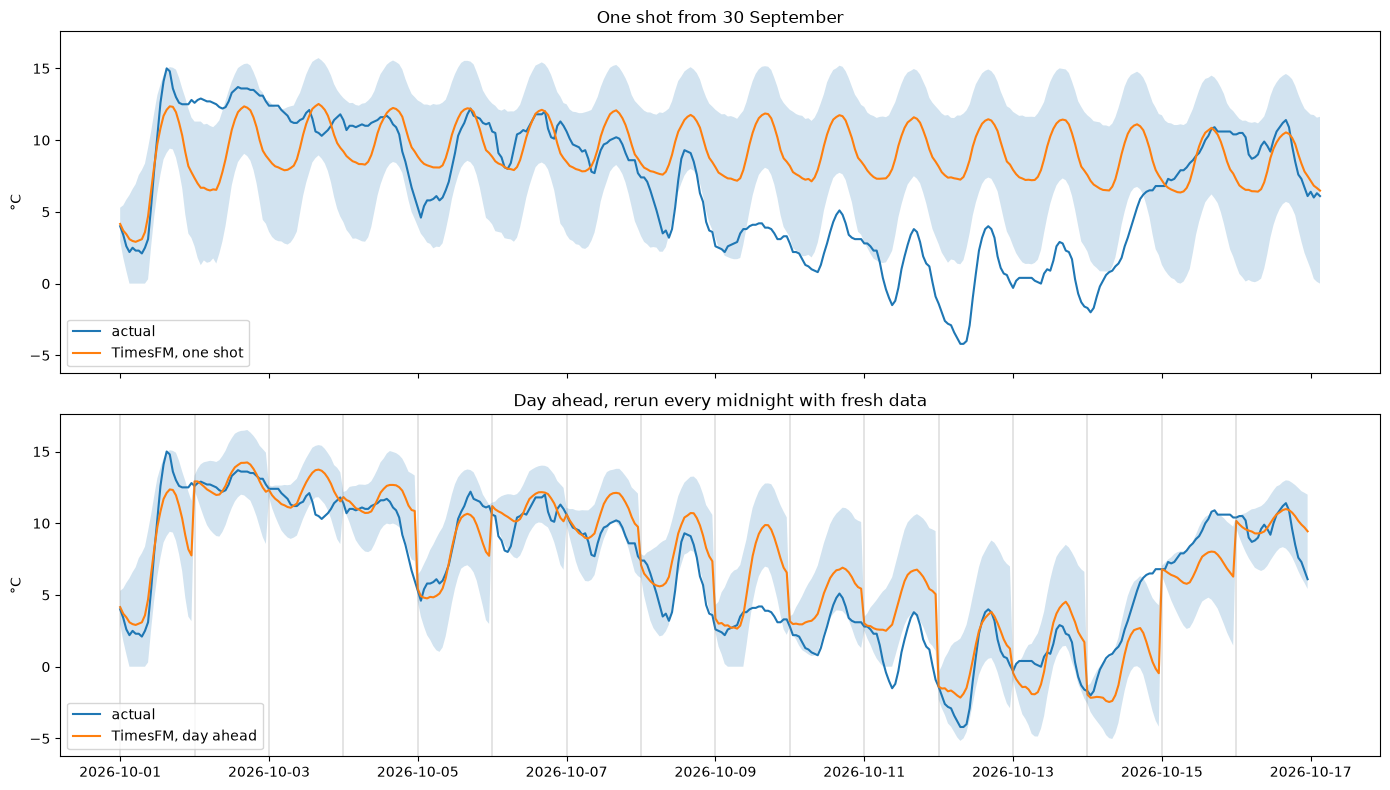

In [28]:
split = pd.Timestamp("2026-10-01", tz=TZ)
s0 = temp.index.get_loc(split)
octo = temp.iloc[s0:]
f1, q1 = forecast([y[s0 - CONTEXT:s0]], len(octo))

last_full_day = (temp.index.max() - pd.Timedelta(hours=23)).normalize()
oct_starts = [temp.index.get_loc(d) for d in pd.date_range(split, last_full_day, freq="D")]
f2, q2 = forecast([y[s - CONTEXT:s] for s in oct_starts], 24)
a2 = np.concatenate([y[s:s + 24] for s in oct_starts])
p2 = np.concatenate([np.repeat(y[s - 1], 24) for s in oct_starts])
idx2 = pd.DatetimeIndex(np.concatenate([temp.index[s:s + 24] for s in oct_starts]))
lo2, hi2 = q2[:, :, 0].ravel(), q2[:, :, 8].ravel()

print(f"One shot MAE:              {np.abs(f1[0] - octo.values).mean():.2f} °C")
print(f"Day ahead persistence MAE: {np.abs(p2 - a2).mean():.2f} °C")
print(f"Day ahead TimesFM MAE:     {np.abs(f2.ravel() - a2).mean():.2f} °C")
print(f"Day ahead band coverage:   {((a2 >= lo2) & (a2 <= hi2)).mean():.0%}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
axes[0].plot(octo.index, octo.values, label="actual")
axes[0].plot(octo.index, f1[0], label="TimesFM, one shot")
axes[0].fill_between(octo.index, q1[0, :, 0], q1[0, :, 8], alpha=0.2)
axes[0].set_title("One shot from 30 September")
axes[1].plot(idx2, a2, label="actual")
axes[1].plot(idx2, f2.ravel(), label="TimesFM, day ahead")
axes[1].fill_between(idx2, lo2, hi2, alpha=0.2)
for s in oct_starts:
    axes[1].axvline(temp.index[s], color="grey", linewidth=0.3)
axes[1].set_title("Day ahead, rerun every midnight with fresh data")
for ax in axes:
    ax.set_ylabel("°C")
    ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 7. Summary

Results from 287 forecasts issued at midnight from 1 January to 14 October 2026.

| | 1h | 6h | 24h | 72h | mean 1-72h | 10-90% band |
|---|---|---|---|---|---|---|
| Persistence | 0.65 | 2.29 | 2.66 | 3.61 | 3.33 | |
| Yesterday | 2.72 | 3.11 | 2.66 | 3.61 | 3.22 | |
| Climatology | 3.85 | 3.88 | 3.87 | 3.82 | 3.94 | |
| TimesFM 3.0, 1 year context | 0.37 | 1.39 | 2.54 | 3.37 | 2.72 | 81% |

MAE in °C.

**What the results show**

- TimesFM beats every baseline at almost every lead time. Averaged over the 72 hours it is 18% better than persistence and 16% better than repeating yesterday.
- The gain is largest in the first hours (about 40% better than persistence at 1 to 6 hours) and shrinks to about 7% at 72 hours.
- Single lead times can mislead. All forecasts start at midnight, so 24, 48 and 72 hours are all midnight, which is exactly when persistence is at its best. Around midday persistence is much worse (see the lead time plot). That is why the mean over all leads is the fairer number.
- The uncertainty is honest. 81 to 82% of actual values fall inside the 10-90% band, close to the ideal 80%, in every context length.
- Winter is the hard part. In January TimesFM was slightly worse than persistence and in February about the same. From March to October it was clearly better every month. Climatology is very poor in winter because cold spells swing far from the long-term average.
- Longer memory helps little. One year of context gave the lowest mean error (2.72), but 3 weeks (2.77) and 3 months (2.84) are close. The paired check above shows whether that gap is real.
- Rerunning matters more than anything. In October a single long forecast had an MAE of 3.92 °C and missed the cold snap completely. Rerun every midnight it dropped to 1.66 °C, 14% better than persistence.

**Limitations and next steps**

- The model only sees past temperatures at one station. Fronts and air masses arriving from elsewhere cause the biggest errors. FMI's forecast sees them, so the next step is to give FMI's forecast to TimesFM as a past-future covariate.
- The live log (section 4) is the start of a fair TimesFM vs FMI comparison.
- No fine-tuning yet. LoRA fine-tuning on 2019 to 2024 with 2025 for validation is a possible follow-up.

Data: Finnish Meteorological Institute open data (CC BY 4.0). Model: TimesFM 3.0 by Google Research (weights under a non-commercial licence).